# Fase 1 — Análisis Exploratorio de Datos (EDA)

Objetivo: entender el dataset de clientes, medir el desbalance de la variable objetivo,
detectar fugas de datos y decidir qué variables entran a la red neuronal.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

from src import config

# Estilo de gráficos
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.axisbelow": True, "axes.titlesize": 11, "font.size": 9,
})
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(config.FIGURES_DIR / name, dpi=150, bbox_inches="tight")

## 1. Carga y revisión general

In [2]:
df = pd.read_csv(config.RAW_DATA_FILE)
print(df.shape)
df.head()

(10000, 18)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


In [3]:
pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "valores_unicos": df.nunique(),
})

,tipo,nulos,valores_unicos
RowNumber,int64,0,10000
CustomerId,int64,0,10000
Surname,str,0,2932
CreditScore,int64,0,460
Geography,str,0,3
Gender,str,0,2
Age,int64,0,70
Tenure,int64,0,11
Balance,float64,0,6382
NumOfProducts,int64,0,4


In [4]:
print("Filas duplicadas:", df.duplicated().sum())
print("CustomerId duplicados:", df["CustomerId"].duplicated().sum())

Filas duplicadas: 0
CustomerId duplicados: 0


10.000 clientes y 18 columnas, sin valores nulos ni duplicados. `RowNumber`, `CustomerId`
y `Surname` son identificadores y no se usan como variables predictivas.

## 2. Variable objetivo (`Exited`)

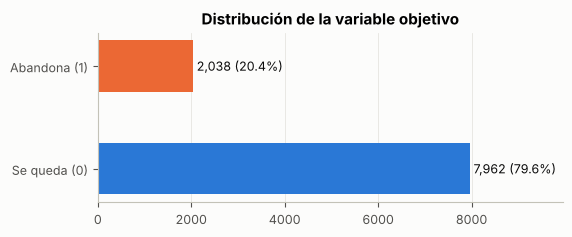

In [5]:
counts = df[config.TARGET].value_counts().sort_index()
pct = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(6, 2.2))
ax.barh(["Se queda (0)", "Abandona (1)"], counts.values, color=[BLUE, ORANGE], height=0.5)
for i, (n, p) in enumerate(zip(counts.values, pct.values)):
    ax.text(n + 80, i, f"{n:,} ({p:.1f}%)", va="center", color="#0b0b0b")
ax.set_xlim(0, counts.max() * 1.25)
ax.set_title("Distribución de la variable objetivo")
ax.grid(axis="y", visible=False)
save(fig, "01_distribucion_objetivo.png")
plt.show()

Solo el **20,4%** de los clientes abandona. El desbalance es moderado: un modelo que dijera
"nadie se va" acertaría casi el 80% sin aprender nada. Por eso se usará `class_weight` en el
entrenamiento y métricas como ROC-AUC y PR-AUC en lugar de la exactitud.

## 3. Detección de fuga de datos (`Complain`)

In [6]:
print(pd.crosstab(df["Complain"], df[config.TARGET], margins=True))
print("\nCorrelación Complain-Exited:", round(df["Complain"].corr(df[config.TARGET]), 4))

Exited       0     1    All
Complain                   
0         7952     4   7956
1           10  2034   2044
All       7962  2038  10000

Correlación Complain-Exited: 0.9957


De 2.044 clientes con queja, 2.034 abandonaron (correlación 0,996). La queja se registra
prácticamente junto con la salida, así que usarla equivale a darle la respuesta a la red.
**`Complain` se excluye del modelo** (data leakage).

## 4. Variables numéricas

In [7]:
num_cols = ["CreditScore", "Age", "Tenure", "Balance", "EstimatedSalary", "Point Earned"]
df[num_cols].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
CreditScore,10000.0,650.5,96.7,350.0,584.0,652.0,718.0,850.0
Age,10000.0,38.9,10.5,18.0,32.0,37.0,44.0,92.0
Tenure,10000.0,5.0,2.9,0.0,3.0,5.0,7.0,10.0
Balance,10000.0,76485.9,62397.4,0.0,0.0,97198.5,127644.2,250898.1
EstimatedSalary,10000.0,100090.2,57510.5,11.6,51002.1,100193.9,149388.2,199992.5
Point Earned,10000.0,606.5,225.9,119.0,410.0,605.0,801.0,1000.0


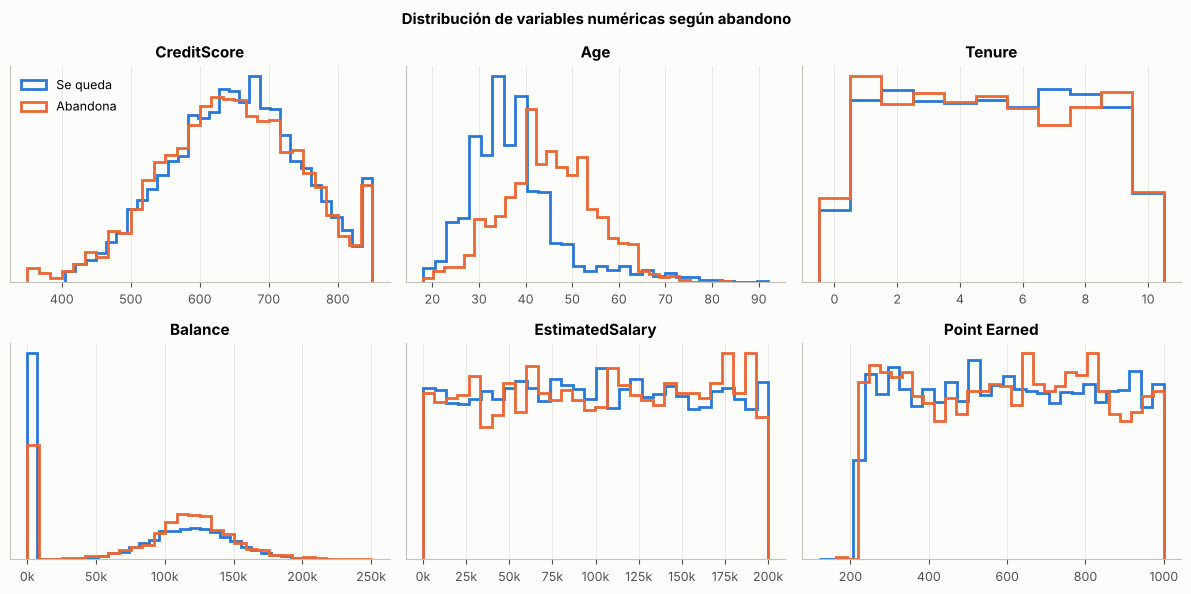

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, col in zip(axes.flat, num_cols):
    for val, color, label in [(0, BLUE, "Se queda"), (1, ORANGE, "Abandona")]:
        bins = np.arange(-0.5, 11.5, 1) if col == "Tenure" else 30
        ax.hist(df.loc[df[config.TARGET] == val, col], bins=bins, density=True,
                histtype="step", linewidth=2, color=color, label=label)
    ax.set_title(col)
    ax.set_yticks([])
    if col in ("Balance", "EstimatedSalary"):
        ax.xaxis.set_major_formatter(lambda x, _: f"{x/1000:.0f}k")
axes[0, 0].legend(frameon=False)
fig.suptitle("Distribución de variables numéricas según abandono", fontweight="bold")
fig.tight_layout()
save(fig, "02_numericas_por_clase.png")
plt.show()

In [9]:
df.groupby(config.TARGET)[num_cols].median().T

Exited,0,1
CreditScore,653.000,646.000
Age,36.000,45.000
Tenure,5.000,5.000
Balance,92063.060,109344.230
EstimatedSalary,99620.355,102489.335
Point Earned,603.000,610.500


In [10]:
edad = pd.cut(df["Age"], [17, 30, 40, 50, 60, 100], labels=["18-30", "31-40", "41-50", "51-60", "60+"])
(df.groupby(edad, observed=True)[config.TARGET].mean() * 100).round(1).rename("% abandono")

Age
18-30     7.5
31-40    12.1
41-50    34.0
51-60    56.2
60+      24.8
Name: % abandono, dtype: float64

- **Edad** es la variable numérica con más diferencia: mediana de 45 años en quienes se van
  contra 36 en quienes se quedan. El abandono sube hasta 56% entre 51 y 60 años.
- **Balance**: quienes se van tienen un saldo mediano algo mayor, lo que confirma que se
  están perdiendo clientes valiosos.
- `CreditScore` muestra una diferencia pequeña; `Tenure`, `EstimatedSalary` y `Point Earned`
  casi no se distinguen entre clases.

In [11]:
cero = df["Balance"] == 0
print(f"Clientes con saldo 0: {cero.mean():.1%}")
print(f"Abandono con saldo 0: {df.loc[cero, config.TARGET].mean():.1%}")
print(f"Abandono con saldo > 0: {df.loc[~cero, config.TARGET].mean():.1%}")
print(df.groupby("Geography")["Balance"].apply(lambda s: (s == 0).mean()).round(3))

Clientes con saldo 0: 36.2%
Abandono con saldo 0: 13.8%
Abandono con saldo > 0: 24.1%
Geography
France     0.482
Germany    0.000
Spain      0.484
Name: Balance, dtype: float64


El 36% de los clientes tiene saldo 0 (ninguno de ellos en Alemania). Esto es importante para
la lógica financiera: el saldo no puede ser la única medida del valor de un cliente.

## 5. Variables categóricas y discretas

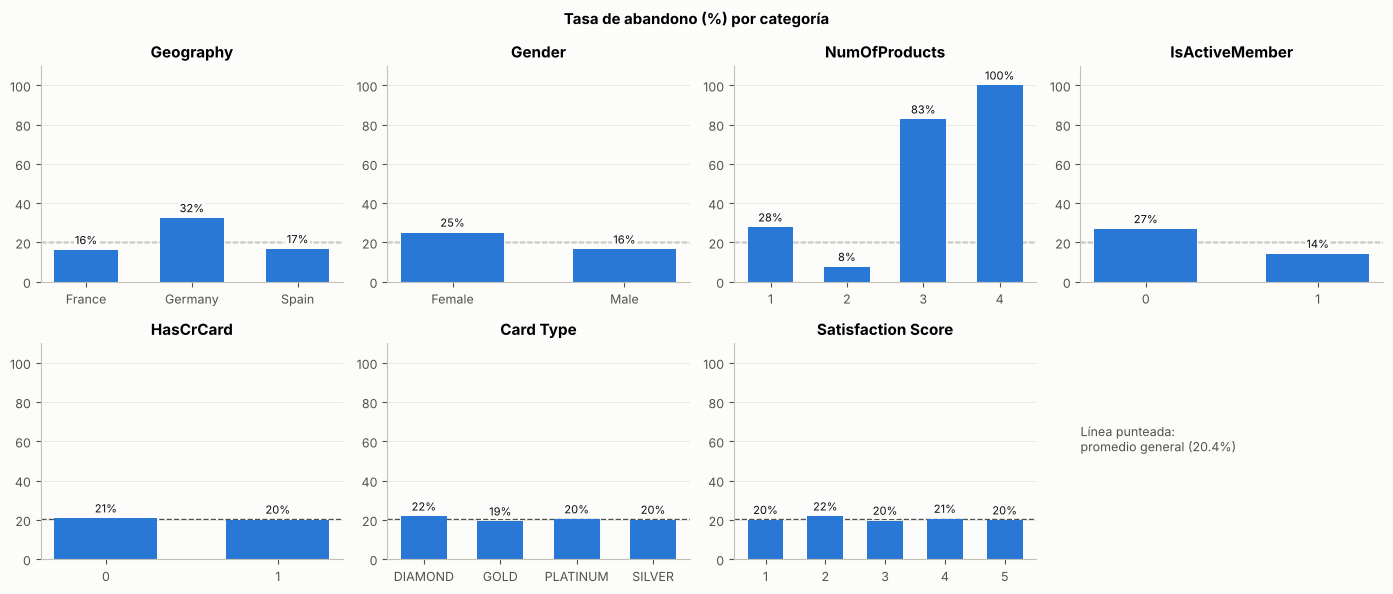

In [12]:
cat_cols = ["Geography", "Gender", "NumOfProducts", "IsActiveMember",
            "HasCrCard", "Card Type", "Satisfaction Score"]
base = df[config.TARGET].mean() * 100

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, col in zip(axes.flat, cat_cols):
    rate = df.groupby(col)[config.TARGET].mean() * 100
    ax.bar(rate.index.astype(str), rate.values, color=BLUE, width=0.6)
    ax.axhline(base, color="#52514e", linestyle="--", linewidth=1, zorder=0)
    for x, v in zip(rate.index.astype(str), rate.values):
        ax.text(x, v + 3, f"{v:.0f}%", ha="center", color="#0b0b0b", fontsize=8,
                bbox=dict(facecolor="#fcfcfb", edgecolor="none", pad=1))
    ax.set_title(col)
    ax.set_ylim(0, 110)
    ax.grid(axis="x", visible=False)
axes.flat[-1].axis("off")
axes.flat[-1].text(0, 0.5, f"Línea punteada:\npromedio general ({base:.1f}%)", color="#52514e")
fig.suptitle("Tasa de abandono (%) por categoría", fontweight="bold")
fig.tight_layout()
save(fig, "03_abandono_por_categoria.png")
plt.show()

- **Geography**: Alemania abandona el 32%, el doble que Francia y España (~16%).
- **Gender**: las mujeres abandonan más (25% contra 17%).
- **IsActiveMember**: los inactivos abandonan casi el doble (27% contra 14%).
- **NumOfProducts**: relación no lineal. Con 2 productos el abandono es mínimo (8%), pero con
  3 sube a 83% y con 4 llega al 100%. Por eso se tratará como **categórica**.
- `HasCrCard`, `Card Type` y `Satisfaction Score` se mantienen cerca del promedio en todas sus
  categorías.

## 6. Pruebas estadísticas de asociación con el abandono

In [13]:
rows = []
for col in ["Geography", "Gender", "NumOfProducts", "IsActiveMember", "HasCrCard",
            "Card Type", "Satisfaction Score"]:
    p = stats.chi2_contingency(pd.crosstab(df[col], df[config.TARGET]))[1]
    rows.append((col, "Chi-cuadrado", p))
for col in num_cols:
    p = stats.mannwhitneyu(df.loc[df[config.TARGET] == 1, col],
                           df.loc[df[config.TARGET] == 0, col]).pvalue
    rows.append((col, "Mann-Whitney U", p))

tests = pd.DataFrame(rows, columns=["variable", "prueba", "p_valor"]).sort_values("p_valor")
tests["asociada (p < 0.05)"] = tests["p_valor"] < 0.05
tests.round(4)

,variable,prueba,p_valor,asociada (p < 0.05)
2,NumOfProducts,Chi-cuadrado,0.0000,True
8,Age,Mann-Whitney U,0.0000,True
0,Geography,Chi-cuadrado,0.0000,True
3,IsActiveMember,Chi-cuadrado,0.0000,True
10,Balance,Mann-Whitney U,0.0000,True
1,Gender,Chi-cuadrado,0.0000,True
7,CreditScore,Mann-Whitney U,0.0218,True
5,Card Type,Chi-cuadrado,0.1679,False
9,Tenure,Mann-Whitney U,0.1730,False
11,EstimatedSalary,Mann-Whitney U,0.2124,False


Con un nivel de significancia de 0,05 no muestran asociación con el abandono: `HasCrCard`,
`Card Type`, `Satisfaction Score`, `Tenure`, `EstimatedSalary` y `Point Earned`.

## 7. Correlaciones

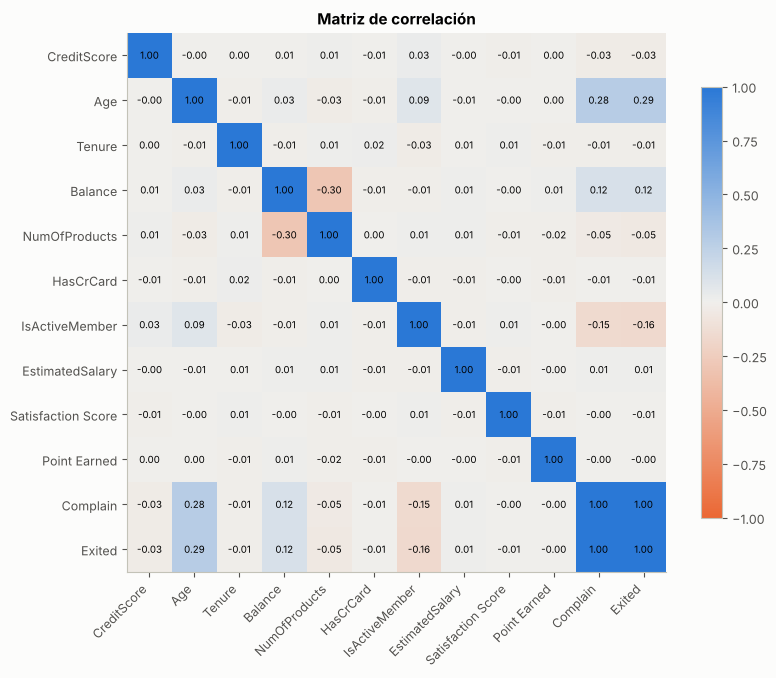

In [14]:
corr_cols = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "HasCrCard",
             "IsActiveMember", "EstimatedSalary", "Satisfaction Score", "Point Earned",
             "Complain", config.TARGET]
corr = df[corr_cols].corr()
cmap = LinearSegmentedColormap.from_list("div", [ORANGE, "#f0efec", BLUE])

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=45, ha="right")
ax.set_yticks(range(len(corr_cols)), corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Matriz de correlación")
save(fig, "04_correlaciones.png")
plt.show()

Fuera de `Complain`, ninguna variable tiene una correlación lineal fuerte con `Exited`
(la mayor es `Age`, 0,29). Tampoco hay correlaciones altas entre variables predictoras, así que
no hay redundancia. Las relaciones no lineales (como `NumOfProducts`) justifican usar una red
neuronal en lugar de un modelo lineal.

## 8. Conclusiones y decisiones para el modelo

| Decisión | Variables | Motivo |
|---|---|---|
| Excluir (identificadores) | `RowNumber`, `CustomerId`, `Surname` | No aportan información predictiva |
| Excluir (fuga de datos) | `Complain` | Correlación 0,996 con `Exited` |
| Excluir (sin señal) | `Card Type`, `Satisfaction Score`, `Point Earned` | Sin asociación con el abandono; son variables de programas y encuestas cuyo momento de registro no se conoce |
| Numéricas (StandardScaler) | `CreditScore`, `Age`, `Tenure`, `Balance`, `EstimatedSalary` | Escalas muy distintas (de 0-10 a 0-250.000) |
| Categóricas (OneHotEncoder) | `Geography`, `Gender`, `NumOfProducts` | `NumOfProducts` tiene relación no lineal con el abandono |
| Binarias (sin cambios) | `HasCrCard`, `IsActiveMember` | Ya están en 0/1 |

`Tenure`, `EstimatedSalary` y `HasCrCard` no son significativas por sí solas, pero se mantienen
por ser variables bancarias estándar: la red puede aprovecharlas en combinación con otras y
SHAP dirá si realmente aportan.

**Factores de abandono preliminares:** edad, país (Alemania), número de productos, inactividad
y género. Se confirmarán con SHAP en la Fase 4.